# 원하는 포즈로 이미지 만들기 (튜토리얼)

사람 사진 한 장에서 **관절(뼈대)** 을 뽑고, 그 뼈대와 **프롬프트**를 함께 넣어 **같은 자세의 다른 인물**을 만드는 도구입니다.

```
사람 사진 → [포즈 추출] → 뼈대 그림 ─┐
                                     ├→ [이미지 생성] → 같은 자세의 다른 인물 → [저장]
프롬프트(영어 문장) ─────────────────┘
```

**사용 모델**
- 그림 본체: Stable Diffusion 1.5 (`stable-diffusion-v1-5/stable-diffusion-v1-5`)
- 포즈 보조(ControlNet): `lllyasviel/sd-controlnet-openpose`
- 뼈대 추출: `controlnet_aux`의 OpenposeDetector

**따라 하는 순서**
1. 위쪽 메뉴 **런타임 → 런타임 유형 변경 → T4 GPU → 저장**
2. 셀을 **위에서부터 한 개씩** 실행 (▶ 버튼 또는 Shift+Enter)
3. 마지막의 실험 기록 칸을 직접 채우기

In [6]:
# [셀 0] 이 셀이 하는 일: 필요한 라이브러리를 설치합니다. (1~2분 걸립니다)
!pip install -q diffusers transformers accelerate controlnet_aux

In [7]:
# [셀 0-2] 이 셀이 하는 일: GPU가 붙었는지 확인합니다.
# 'GPU가 안 붙었습니다'가 나오면 런타임 유형을 T4 GPU로 바꾸고 처음부터 다시 실행하세요.
import torch

if not torch.cuda.is_available():
    raise SystemExit('GPU가 안 붙었습니다. 런타임 유형을 T4 GPU로 바꾸고 다시 실행하세요.')

p = torch.cuda.get_device_properties(0)
print(f'{p.name} / VRAM {p.total_memory / 1024**3:.1f}GB')

Tesla T4 / VRAM 14.6GB


In [5]:
# [셀 1: 모델 로드] 이 셀이 하는 일: 그림을 그리는 모델(Stable Diffusion 1.5)과
# 포즈를 따르게 하는 보조 모델(ControlNet)을 내려받아 GPU에 올립니다. (처음엔 몇 분 걸립니다)
import torch
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel, UniPCMultistepScheduler

controlnet = ControlNetModel.from_pretrained(
    'lllyasviel/sd-controlnet-openpose', torch_dtype=torch.float16
)
pipe = StableDiffusionControlNetPipeline.from_pretrained(
    'stable-diffusion-v1-5/stable-diffusion-v1-5',
    controlnet=controlnet,
    torch_dtype=torch.float16,
).to('cuda')
pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)
print('모델 로드 완료')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/920 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 1.45GB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

... (2 outputs left out)

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

모델 로드 완료


Saving 2.jpg to 2.jpg


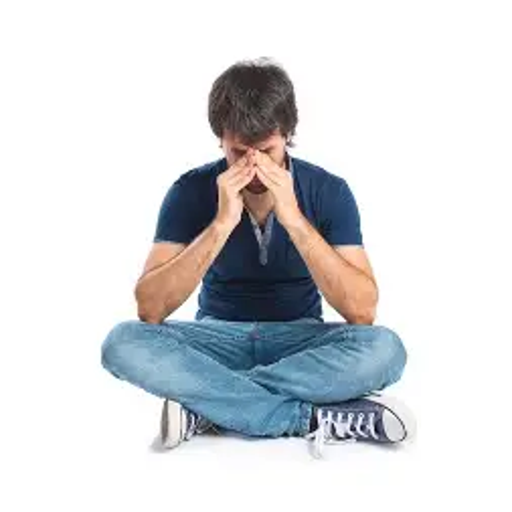

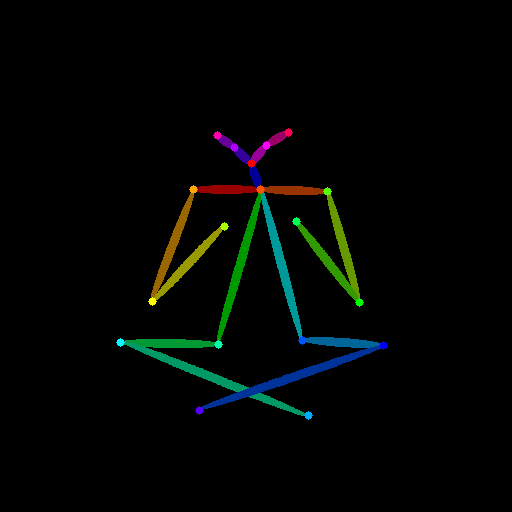

In [12]:
# [셀 2: 포즈 추출] 이 셀이 하는 일: 사람 사진 한 장을 올리면, 그 사진에서 관절(뼈대) 그림을 뽑아 pose에 저장합니다.
# 팁: 몸 전체가 또렷하게 보이는 사진이 좋습니다. 손이 작게 찍히면 관절이 흔들릴 수 있습니다.
from google.colab import files
from PIL import Image
from controlnet_aux import OpenposeDetector

uploaded = files.upload()  # 파일 선택 창이 뜹니다. 사람 사진 한 장을 고르세요.
ref = Image.open(list(uploaded.keys())[0]).convert('RGB').resize((512, 512))

openpose = OpenposeDetector.from_pretrained('lllyasviel/Annotators')
pose = openpose(ref)
pose.save('pose_01.png')

# 원본 사진과 뼈대를 나란히 보여 줍니다.
from IPython.display import display
display(ref, pose)

  0%|          | 0/20 [00:00<?, ?it/s]

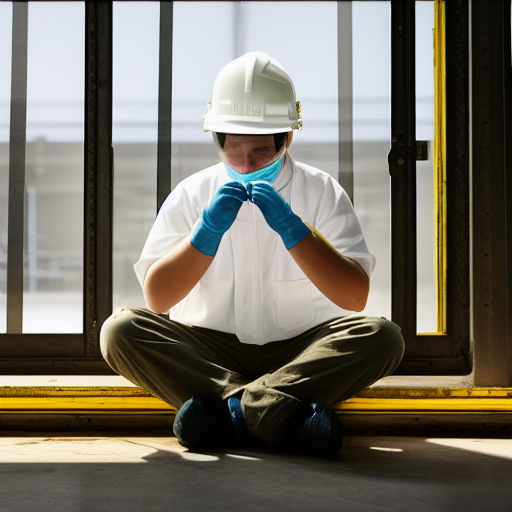

In [13]:
# [셀 3: 이미지 생성] 이 셀이 하는 일: 뼈대(pose)와 프롬프트로 같은 자세의 새 그림을 만듭니다.
# 시드(SEED)를 고정해 두면, 프롬프트만 바꿨을 때 무엇이 달라지는지 비교할 수 있습니다.
from IPython.display import display

SEED = 42

def generate(prompt, pose_img, seed=SEED, steps=20):
    g = torch.Generator('cuda').manual_seed(seed)
    return pipe(prompt, image=pose_img, num_inference_steps=steps, generator=g).images[0]

prompt = (
    'A factory worker in a white safety helmet, medium shot, '
    'soft morning light from tall windows on the left, '
    'photorealistic documentary photography'
)
out = generate(prompt, pose)
display(out)

In [15]:
# [셀 4: 결과 저장] 이 셀이 하는 일: 결과 그림과 뼈대 그림을 파일로 저장하고 내 컴퓨터로 내려받습니다.
# 내려받은 파일은 GitHub 저장소의 samples/ 폴더에 넣습니다.
from google.colab import files

out.save('output_01.png')
files.download('pose_01.png')
files.download('output_01.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 실험 A: 같은 포즈, 프롬프트만 바꾸기
아래 셀은 **같은 뼈대, 같은 시드**에서 프롬프트만 바꿔 세 장을 만듭니다. 프롬프트를 마음대로 고쳐 보세요.

  0%|          | 0/20 [00:00<?, ?it/s]

A1 → A factory worker in a white safety helmet, soft morning light, photorealistic documentary photography


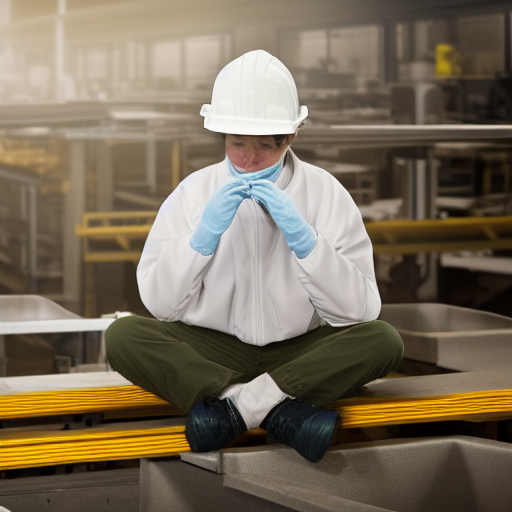

  0%|          | 0/20 [00:00<?, ?it/s]

A2 → An astronaut in a white spacesuit, bright studio lighting, photorealistic


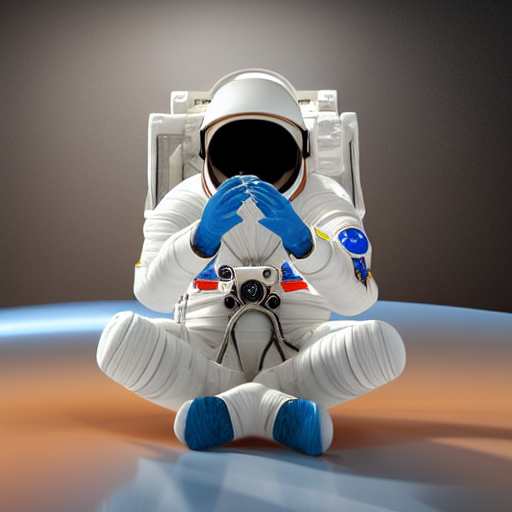

  0%|          | 0/20 [00:00<?, ?it/s]

A3 → A chef in a white uniform in a kitchen, warm light, watercolor illustration


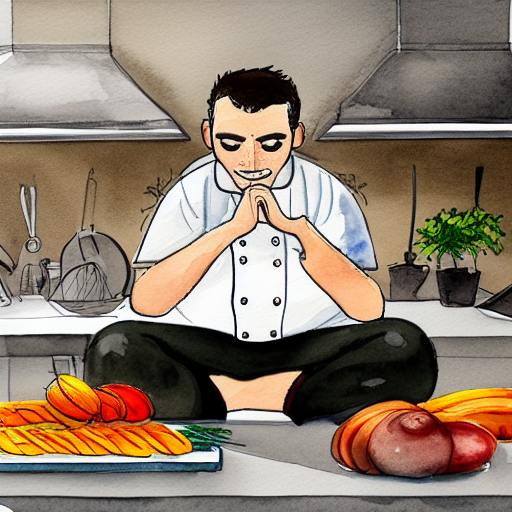

In [17]:
# [실험 A] 이 셀이 하는 일: 같은 포즈(pose)와 같은 시드로, 프롬프트만 바꿔 여러 장을 만듭니다.
# 프롬프트를 직접 고쳐서 어떤 부분이 바뀌는지 관찰하세요.
from IPython.display import display

prompts_A = {
    'A1': 'A factory worker in a white safety helmet, soft morning light, photorealistic documentary photography',
    'A2': 'An astronaut in a white spacesuit, bright studio lighting, photorealistic',
    'A3': 'A chef in a white uniform in a kitchen, warm light, watercolor illustration',
}

for name, text in prompts_A.items():
    img = generate(text, pose)
    img.save(f'output_{name}.png')
    print(name, '→', text)
    display(img)

## 실험 B: 같은 프롬프트, 다른 포즈 사진
1. **셀 2**를 다시 실행해서 **다른 자세의 사진**을 올립니다. (뼈대가 새로 만들어져 `pose`가 바뀝니다.)
2. 아래 셀을 실행합니다. 프롬프트는 그대로, 시드도 그대로입니다.

  0%|          | 0/20 [00:00<?, ?it/s]

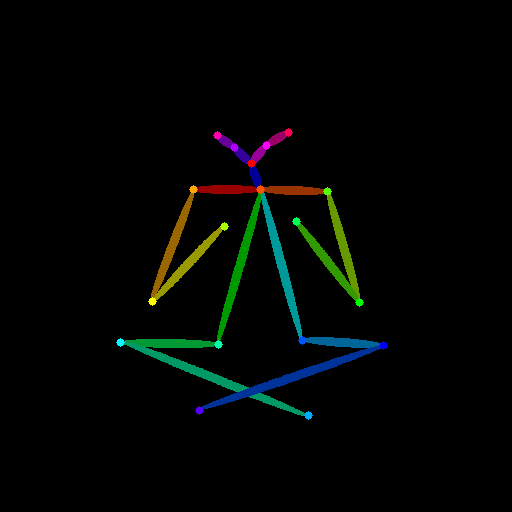

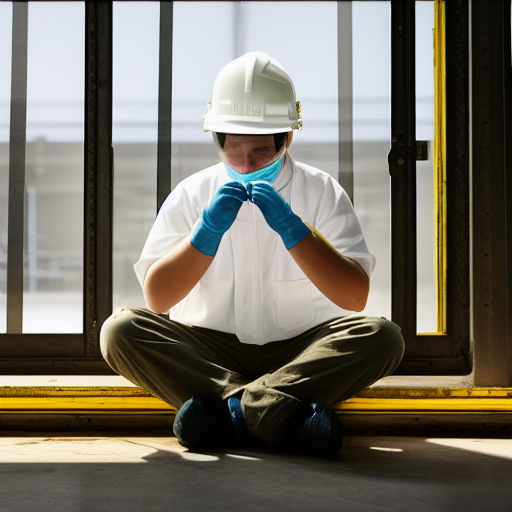

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [18]:
# [실험 B] 이 셀이 하는 일: 셀 3과 같은 프롬프트로, 새로 올린 포즈(pose)에서 그림을 만듭니다.
# 파일 이름의 숫자를 02, 03처럼 바꿔 가며 저장하세요.
from IPython.display import display
from google.colab import files

pose.save('pose_02.png')
out_b = generate(prompt, pose)
out_b.save('output_02.png')
display(pose, out_b)
files.download('pose_02.png')
files.download('output_02.png')

## 실험 기록

### 사용한 설정
- 모델: Stable Diffusion 1.5 + OpenPose ControlNet (`lllyasviel/sd-controlnet-openpose`)
- 시드: 42 (고정) / 스텝: 20
- 실행 환경: Google Colab 무료 GPU
- 라이선스: 모델 페이지에서 확인해 README에 적었습니다.

### 실험 A: 같은 포즈, 프롬프트만 바꿈
시드와 뼈대는 그대로 두고 프롬프트만 바꿨습니다.

| 번호 | 프롬프트(요약) | 달라진 점 | 자세는 유지되었나 |
|---|---|---|---|
| A1 | 공장 작업자, 사진풍 | 자세가 정확하게 나왔지만 손이 부정확하고, 손가락 관절이 하나하나 구분되지 않고 통으로 뭉쳐 보였다. | 유지됨 |
| A2 | 우주비행사, 스튜디오 조명 | 손과 손가락이 어색하고, 발목과 발이 떨어져 있는 것처럼 보였다. | 대체로 유지됨 |
| A3 | 요리사, 수채화풍 | 손가락이 두툼하게 뭉치고 팔 표현이 어색했다. | 유지됨 (팔은 어색) |

### 실험 B: 같은 프롬프트, 다른 포즈
프롬프트(`A factory worker in a white safety helmet …`)와 시드는 그대로 두고 참조 사진만 바꿨습니다.

| 번호 | 포즈 사진 설명 | 결과 | 잘 따라온 부분 / 안 따라온 부분 |
|---|---|---|---|
| B1 | 뼈대에 사람이 세 명 잡힌, 달리는 자세 | 안전모와 흰 작업복을 입은 사람이 세 명 나왔다. 그중 한 명은 유리창에 비친 것처럼 흐렸다. | 달리는 자세와 팔다리 방향은 잘 따라옴. 프롬프트는 한 명이었지만 인원수는 뼈대를 따라 세 명이 됨. |
| B2 | 양반다리로 앉은 자세 | 앉은 자세와 손을 모은 모습이 뼈대와 같게 나왔고, 안전모와 장갑도 프롬프트대로 나왔다. | 자세는 잘 따라옴. 손 부분은 단순하게 뭉쳐 보임. |

### 알게 된 점
- **포즈를 바꿨을 때:** 인원수, 구도, 자세가 완전히 달라졌습니다. 같은 프롬프트와 같은 시드여도 뼈대가 장면의 구조를 정했습니다. 뼈대에 사람이 여러 명이면 프롬프트에 한 명이라고 써도 여러 명이 나왔습니다.
- **프롬프트를 바꿨을 때:** 자세는 거의 그대로 따라오고 인물, 옷, 조명, 그림 느낌만 바뀌었습니다. 포즈 조건이 프롬프트와 별개로 자세를 잡아 준다는 것을 확인했습니다.
- **잘 안 따라온 것:** 어떤 프롬프트와 포즈에서도 손과 손가락, 발목과 발의 연결이 계속 약했습니다. OpenPose 뼈대는 손가락 관절 정보가 없고 손목까지만 알려 주기 때문에, 세부는 모델이 정해야 해서 그런 것으로 추측합니다. (이 원인은 확인한 것이 아니라 추측입니다.)
- **다음에 해 보고 싶은 것:**
  - 손이 작게 보이거나 가려지는 구도의 사진으로 비교하기
  - 스텝 수(20 → 30)와 시드를 바꿔 여러 장 뽑아 손이 나아지는지 보기
  - 다른 모델(SDXL 등)로 같은 포즈를 돌려 손이 달라지는지 비교하기